Parkinson's Model


c:\Users\yashk\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\normalization\batch_normalization.py:142: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


<Axes: title={'center': 'Accuracy'}>

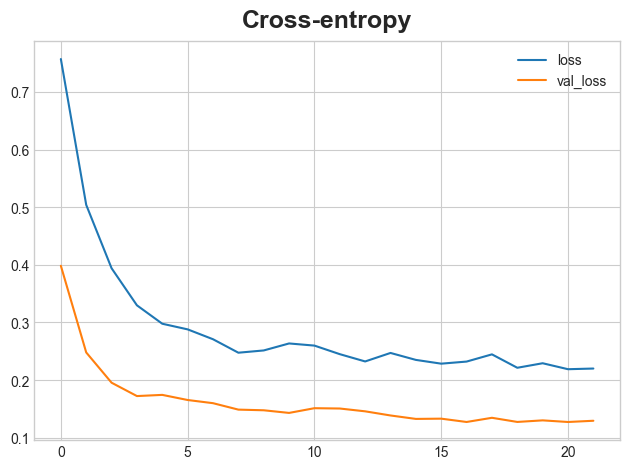

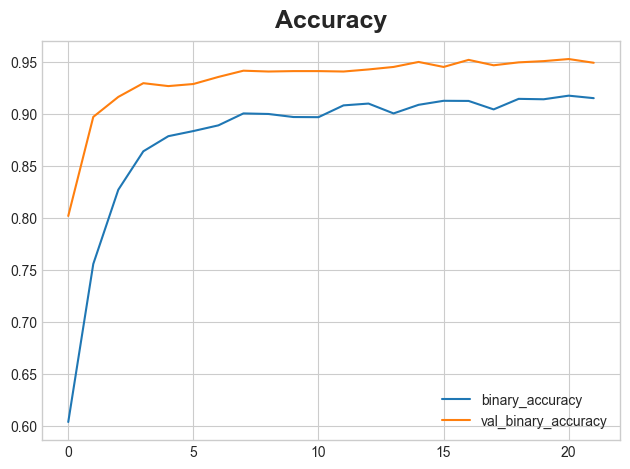

In [1]:
print("Parkinson's Model")
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.initializers import lecun_normal

import os

plt.style.use('seaborn-v0_8-whitegrid')

plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large', titleweight='bold', titlesize=18, titlepad=10)
plt.rc('animation', html='html5')

# Load dataset
tremor_data = pd.read_csv("parkinsons_tremor_dataset.csv")
X = tremor_data.copy()
y = X.pop('label')

# Split dataset
X_train, X_valid, y_train, y_valid = train_test_split(X, y, random_state=42)

# Define the model with SELU and LeCun Normal initialization
model = keras.Sequential([
    layers.BatchNormalization(input_shape=[7]),
    layers.Dense(units=128, activation='selu', kernel_initializer=lecun_normal()),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(units=128, activation='selu', kernel_initializer=lecun_normal()),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(units=128, activation='selu', kernel_initializer=lecun_normal()),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(units=128, activation='selu', kernel_initializer=lecun_normal()),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(units=1, activation='sigmoid')  # Output layer for binary classification
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

# Early stopping callback
early_stopping = keras.callbacks.EarlyStopping(
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=30,
    epochs=200,
    verbose=0,
    callbacks=[early_stopping],
)

# Plot training history
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy")
history_df.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")
